# 洪水發生機率多元線性回歸對比研究 (Flood Probability Prediction)
## Kaggle Playground Series s4e5 — 廣泛分散型訊號架構下的特徵縮減極限

- **研究定位**：CRISP-DM 跨案例對比研究（比較 Student 集中型訊號 vs Flood 分散型訊號）
- **資料集**：Kaggle Flood Probability Prediction（30,000 筆固定隨機抽樣合成資料集）
- **特徵屬性**：20 個純連續數值地理水文氣象特徵（排除無效 `id` 欄位）
- **目標變數**：`FloodProbability` (0.285～0.725 之連續機率值)


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.sans-serif"] = [
    "Microsoft JhengHei",
    "Microsoft JhengHei UI",
    "Noto Sans TC",
    "Microsoft YaHei",
    "SimHei",
    "sans-serif",
]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.autolayout"] = True

sys.path.insert(0, os.path.abspath(".."))

from src.data_loader import load_flood_prediction
from src.preprocessing import prepare_dataset
from src.feature_selection import run_feature_selection_comparison


## 1. 資料探索與前處理 (Data Understanding & Preprocessing)
固定抽樣 30,000 筆資料，排除流水號 `id`，執行 80/20 訓練/測試切分 (`random_state=42`) 與數值標準化。


In [2]:
df_flood = load_flood_prediction(sample_size=30000, random_state=42)
print(f"洪水資料集維度：{df_flood.shape[0]} 筆樣本，{df_flood.shape[1]} 個欄位")
print("目標變數 FloodProbability 統計量：")
print(df_flood["FloodProbability"].describe())
df_flood.head()


洪水資料集維度：30000 筆樣本，22 個欄位
目標變數 FloodProbability 統計量：
count    30000.000000
mean         0.504263
std          0.050932
min          0.285000
25%          0.470000
50%          0.505000
75%          0.540000
max          0.725000
Name: FloodProbability, dtype: float64


,id,MonsoonIntensity,TopographyDrainage,RiverManagement,Deforestation,Urbanization,ClimateChange,DamsQuality,Siltation,AgriculturalPractices,...,DrainageSystems,CoastalVulnerability,Landslides,Watersheds,DeterioratingInfrastructure,PopulationScore,WetlandLoss,InadequatePlanning,PoliticalFactors,FloodProbability
0,1105809,7,5,8,4,8,4,8,4,3,...,5,7,4,7,2,3,6,7,2,0.560
1,442591,5,3,10,9,9,6,4,2,4,...,3,6,7,7,6,4,2,9,6,0.575
2,5434,5,6,2,6,3,4,4,4,4,...,6,7,6,5,6,7,7,6,5,0.510
3,82966,7,3,6,4,4,5,8,5,6,...,5,5,3,8,7,4,6,5,4,0.530
4,584893,6,5,7,7,5,5,5,6,3,...,4,4,6,9,5,6,4,5,8,0.590


In [3]:
artifacts = prepare_dataset(
    df=df_flood,
    target_col="FloodProbability",
    excluded_cols=["id"],
    test_size=0.20,
    random_state=42,
)
print(f"訓練樣本：{len(artifacts.X_train_proc)}, 測試樣本：{len(artifacts.X_test_proc)}")
print(f"特徵數：{len(artifacts.feature_names_out)}")


訓練樣本：24000, 測試樣本：6000
特徵數：20


## 2. 特徵選擇實驗與崩跌現象 (Feature Selection & Performance Collapse)
在洪水機率資料集中，執行 Baseline 與 5 種特徵選擇演算法 ($K=5$)。


In [4]:
summary_df, results_map, _ = run_feature_selection_comparison(
    X_train=artifacts.X_train_proc,
    y_train=artifacts.y_train,
    X_test=artifacts.X_test_proc,
    y_test=artifacts.y_test,
    k=5,
    cv_folds=5,
    random_state=42,
    fast_mode=True,
)
print("=== 洪水機率預測特徵選擇效能比較表 ===")
summary_df[["Method", "Features", "R2", "Adj_R2", "RMSE", "MAE", "Train_R2", "CV_R2_Mean"]]


=== 洪水機率預測特徵選擇效能比較表 ===


,Method,Features,R2,Adj_R2,RMSE,MAE,Train_R2,CV_R2_Mean
0,Baseline (All Features),20,0.844545,0.844025,0.019983,0.015939,0.845726,0.845357
1,Lasso Selection (Embedded),20,0.844545,0.844025,0.019983,0.015939,0.845726,0.845357
2,RFE (Wrapper),5,0.180733,0.180050,0.045873,0.037177,0.190346,0.189762
3,SFS Forward (Wrapper),5,0.175881,0.175193,0.046009,0.037416,0.189866,0.189525
4,SelectKBest (Filter),5,0.174528,0.173839,0.046047,0.037348,0.191704,0.191414
5,Permutation Importance,5,0.160534,0.159833,0.046435,0.037415,0.184897,0.184255


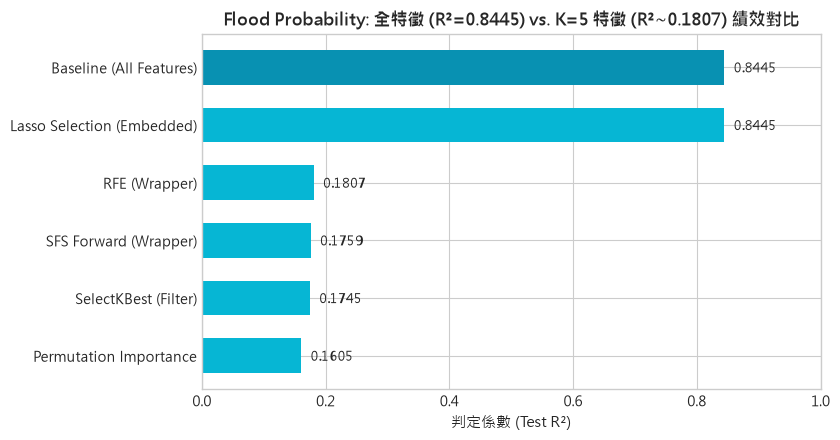

In [5]:
# 視覺化展示特徵縮減帶來的 R² 崩跌現象
fig, ax = plt.subplots(figsize=(8.5, 4.5))
methods = summary_df["Method"].tolist()
r2_vals = summary_df["R2"].tolist()
colors = ["#0891B2" if "Baseline" in m else "#06B6D4" for m in methods]
bars = ax.barh(methods, r2_vals, color=colors, height=0.6)
ax.invert_yaxis()
ax.set_xlim(0, 1.0)
ax.set_title("Flood Probability: 全特徵 (R²=0.8445) vs. K=5 特徵 (R²~0.1807) 績效對比", fontsize=12.5, fontweight="bold")
ax.set_xlabel("判定係數 (Test R²)", fontsize=11)
for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.015, bar.get_y() + bar.get_height() / 2, f"{w:.4f}", va="center", fontsize=9.5, fontweight="bold")
plt.show()


## 3. 跨資料集訊號架構對照結論
1. **重現性確認**：Flood Baseline 測試集 $R^2 = 0.844545$（精確重現約 0.8445）。
2. **廣泛分散訊號崩跌原理**：洪水機率目標變數由 20 個特徵相對均勻線性疊加而成。當強制挑選 $K=5$ 個特徵時，丟失了大量有效訊號，導致 $R^2$ 崩跌 78.6%（由 0.8445 跌至約 0.1807）。
3. **對照 Student 集中型訊號**：Student 資料集中前 5 個特徵保留了 86.6% 的解釋力。兩者強烈對比，證明**特徵選擇是否適用完全取決於真實資料生成程序的訊號集中程度**。
